<a href="https://colab.research.google.com/github/Nousiba/Concrete-Crack-Segmentation/blob/main/Concrete_Crack_Phase1_2_v5_Copy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Concrete Crack Segmentation: Phase 1 (Topic) and Phase 2 (Baselines)

CSE281 Digital Image Processing course project. This notebook covers only the first two
checkpoints: **1. Topic settled** and **2. Baselines ready**.

**How to run it (any machine, any Colab account):**
1. Put the dataset folder anywhere on your machine so that it contains two sub-folders:
   `rgb/` (photos) and `BW/` (binary crack masks). The names are not case sensitive.
2. Run the cells from top to bottom. The notebook searches for the folder by itself.
3. If it cannot find it, it asks you to upload a `.zip` of the dataset (Colab), or you can
   set the environment variable `CRACK_DATASET` to the folder path.

No path in this notebook belongs to a specific person or Google Drive.

## 1. Problem statement and primary metric

**User and task.** A civil-inspection engineer photographs concrete surfaces and needs the
cracked pixels marked so that the cracked area (percentage of the image) can be reported.

**Input.** One colour photo, 8-bit per channel (uint8, 0 to 255), JPEG. The loader keeps the
colour image for display, converts it to grayscale for processing, and resizes it so that the
longest side is at most `MAX_SIDE` pixels (the full-size photos are too large for a free
Colab CPU to process in the 10-minute limit).

**Output.** A binary mask (1 = crack, 0 = background) and the cracked-area percentage.

**Cost of errors.** A missed crack (false negative) can hide a structural problem. A false
alarm (false positive) wastes inspection time. Cracks cover only a very small fraction of the
pixels, so plain pixel accuracy would be above 95 % even for an empty mask.

**Primary metric: IoU** = |A ∩ B| / |A ∪ B|. It punishes both missed crack pixels and false
alarms and ignores the large true-negative background, so it is not fooled by the class
imbalance. Precision and recall are reported as secondary metrics to show which error type
dominates.

**Dataset.** Concrete Crack Segmentation Dataset, Mendeley Data (458 high-resolution photos,
each with a binary crack mask). Source: https://data.mendeley.com/datasets/jwsn7tfbrp/1 . Licence: CC BY 4.0
(Creative Commons Attribution 4.0), checked on the dataset page.

## 2. Setup and dataset discovery

In [1]:
import os
import sys
import time
import zipfile
import datetime
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------- configuration (the only place to edit) ----------------
AUTHOR = 'team'          # your name, written into the experiment log
SEED = 42                # fixed seed for the split and any random sampling
MAX_SIDE = 1024          # longest image side after loading (keeps Colab fast)
TEST_FRACTION = 0.30     # 70 / 30 development / test split
USE_DRIVE = 'google.colab' in sys.modules   # in Colab: mount Drive automatically
OUT_DIR = Path('outputs')
# -------------------------------------------------------------------------

OUT_DIR.mkdir(exist_ok=True)
cv2.setRNGSeed(SEED)

if USE_DRIVE:
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except Exception as err:   # no Drive access: the dataset search falls back to a zip upload
        print('Drive not mounted:', err)

Mounted at /content/drive


In [2]:
def _pair_in(folder):
    """Return (rgb_dir, bw_dir) if `folder` has both sub-folders, else None."""
    subs = {p.name.lower(): p for p in Path(folder).iterdir() if p.is_dir()}
    if 'rgb' in subs and 'bw' in subs:
        return subs['rgb'], subs['bw']
    return None


def find_dataset(extra_roots=(), max_depth=4):
    """Search likely places for a folder that contains rgb/ and BW/."""
    roots = [os.environ.get('CRACK_DATASET'), *extra_roots, 'CrackDataset',
             'data', '.', '/content', '/content/drive/MyDrive']
    for root in roots:
        if not root or not os.path.isdir(root):
            continue
        base_depth = str(root).rstrip(os.sep).count(os.sep)
        for dirpath, dirnames, _ in os.walk(root):
            dirnames[:] = [d for d in dirnames
                           if not d.startswith('.') and d != 'outputs']
            if dirpath.count(os.sep) - base_depth > max_depth:
                dirnames[:] = []
                continue
            found = _pair_in(dirpath)
            if found:
                return found
    return None


def upload_zip_colab():
    """Colab only: ask for a zip file and unpack it to ./CrackDataset."""
    from google.colab import files
    print('Upload a .zip that contains the rgb/ and BW/ folders.')
    uploaded = files.upload()
    for name in uploaded:
        if name.lower().endswith('.zip'):
            with zipfile.ZipFile(name) as zf:
                zf.extractall('CrackDataset')


DATA = find_dataset()
if DATA is None:
    try:
        upload_zip_colab()
        DATA = find_dataset(['CrackDataset'])
    except ImportError:
        pass

if DATA is None:
    raise FileNotFoundError(
        'Dataset not found. Put a folder containing rgb/ and BW/ next to this '
        'notebook, or set the CRACK_DATASET environment variable to its path.')

RGB_DIR, BW_DIR = DATA
print('Using images :', RGB_DIR)
print('Using masks  :', BW_DIR)

Using images : drive/MyDrive/CrackDataset/CrackDataset/rgb
Using masks  : drive/MyDrive/CrackDataset/CrackDataset/BW


## 3. Pairing images and masks

In [3]:
EXT = ('.jpg', '.jpeg', '.png')
rgb_lookup = {p.stem: p.name for p in RGB_DIR.iterdir() if p.suffix.lower() in EXT}
bw_lookup = {p.stem: p.name for p in BW_DIR.iterdir() if p.suffix.lower() in EXT}

names = sorted(set(rgb_lookup) & set(bw_lookup))
data = pd.DataFrame({'image': [rgb_lookup[n] for n in names],
                     'mask': [bw_lookup[n] for n in names]})

print('RGB images            :', len(rgb_lookup))
print('BW masks              :', len(bw_lookup))
print('Matching pairs        :', len(data))
print('Images without masks  :', len(set(rgb_lookup) - set(bw_lookup)))
print('Masks without images  :', len(set(bw_lookup) - set(rgb_lookup)))
assert len(data) > 0, 'No image/mask pairs found'

RGB images            : 445
BW masks              : 458
Matching pairs        : 445
Images without masks  : 0
Masks without images  : 13


## 4. One loader for the whole project

Every later cell loads images through `load_pair`. It returns the colour image (RGB, for
display), the grayscale image (uint8, 0 to 255, used by all processing) and the binary mask
(uint8, 0/1). Images are shrunk with `INTER_AREA` and masks with `INTER_NEAREST` so that mask
values stay strictly 0 or 1.

In [4]:
def load_pair(image_name, mask_name, max_side=MAX_SIDE):
    """Load one image and its mask. Returns (rgb, gray, mask).

    rgb : uint8 (H, W, 3), 0..255, RGB order.
    gray: uint8 (H, W), 0..255.
    mask: uint8 (H, W), values 0 or 1 (1 = crack).
    """
    bgr = cv2.imread(str(RGB_DIR / image_name), cv2.IMREAD_COLOR)
    raw = cv2.imread(str(BW_DIR / mask_name), cv2.IMREAD_GRAYSCALE)
    if bgr is None:
        raise FileNotFoundError(f'Could not read image: {image_name}')
    if raw is None:
        raise FileNotFoundError(f'Could not read mask: {mask_name}')

    h, w = bgr.shape[:2]
    if raw.shape != (h, w):
        raw = cv2.resize(raw, (w, h), interpolation=cv2.INTER_NEAREST)

    scale = max_side / max(h, w)
    if scale < 1.0:
        size = (int(round(w * scale)), int(round(h * scale)))
        bgr = cv2.resize(bgr, size, interpolation=cv2.INTER_AREA)
        raw = cv2.resize(raw, size, interpolation=cv2.INTER_NEAREST)

    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    gray = cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY)
    mask = (raw > 127).astype(np.uint8)
    return rgb, gray, mask


_rgb, _gray, _mask = load_pair(data.iloc[0]['image'], data.iloc[0]['mask'])
print('rgb :', _rgb.shape, _rgb.dtype, _rgb.min(), '-', _rgb.max())
print('gray:', _gray.shape, _gray.dtype, _gray.min(), '-', _gray.max())
print('mask:', _mask.shape, _mask.dtype, np.unique(_mask))

rgb : (1024, 768, 3) uint8 53 - 213
gray: (1024, 768) uint8 57 - 208
mask: (1024, 768) uint8 [0 1]


## 5. Metrics, tested on small arrays worked by hand

* IoU example: intersection = 3 pixels, union = 5 pixels, so IoU = 3/5 = 0.6.
* MSE example: differences are 0, 5, 0, -5, so MSE = (0 + 25 + 0 + 25) / 4 = 12.5.
* PSNR = 10 log10(255² / 12.5) = 37.16 dB.

In [5]:
def iou_score(true_mask, pred_mask):
    """Intersection over union of two binary masks (1.0 if both are empty)."""
    a = true_mask.astype(bool)
    b = pred_mask.astype(bool)
    union = np.logical_or(a, b).sum()
    if union == 0:
        return 1.0
    return float(np.logical_and(a, b).sum() / union)


def precision_recall(true_mask, pred_mask):
    """Pixel precision and recall of a predicted binary mask."""
    a = true_mask.astype(bool)
    b = pred_mask.astype(bool)
    tp = np.logical_and(a, b).sum()
    precision = tp / b.sum() if b.sum() else 0.0
    recall = tp / a.sum() if a.sum() else 1.0
    return float(precision), float(recall)


def mse_score(ref, img):
    """Mean squared error between two arrays."""
    d = ref.astype(np.float64) - img.astype(np.float64)
    return float(np.mean(d ** 2))


def psnr_score(ref, img):
    """PSNR in dB for 8-bit data (inf for identical arrays)."""
    mse = mse_score(ref, img)
    if mse == 0:
        return float('inf')
    return float(10 * np.log10(255.0 ** 2 / mse))


def count_error(true_count, pred_count):
    """Absolute difference between two object counts."""
    return abs(int(true_count) - int(pred_count))


# ---- tests against values computed by hand ----
t = np.array([[1, 1, 0], [0, 1, 0], [0, 0, 1]])
p = np.array([[1, 0, 0], [0, 1, 1], [0, 0, 1]])
assert abs(iou_score(t, p) - 0.6) < 1e-12
assert iou_score(np.zeros((2, 2)), np.zeros((2, 2))) == 1.0
assert iou_score(t, t) == 1.0

o = np.array([10, 20, 30, 40])
q = np.array([10, 25, 30, 35])
assert mse_score(o, q) == 12.5
assert abs(psnr_score(o, q) - 37.1615) < 1e-3
assert psnr_score(o, o) == float('inf')
assert count_error(5, 3) == 2
print('IoU =', iou_score(t, p), '| MSE =', mse_score(o, q),
      '| PSNR =', round(psnr_score(o, q), 4), '| all metric tests passed')

IoU = 0.6 | MSE = 12.5 | PSNR = 37.1617 | all metric tests passed


## 6. Development / test split

Fixed seed, 70 % development and 30 % test. The test set is **not used again** in this
notebook: every number below comes from the development set only.

In [6]:
rng = np.random.default_rng(SEED)
perm = rng.permutation(len(data))
n_test = int(round(len(data) * TEST_FRACTION))

test_data = data.iloc[perm[:n_test]].sort_values('image').reset_index(drop=True)
dev_data = data.iloc[perm[n_test:]].sort_values('image').reset_index(drop=True)

assert not set(dev_data['image']) & set(test_data['image']), 'dev/test overlap'
assert len(dev_data) + len(test_data) == len(data)

dev_data.to_csv(OUT_DIR / 'development_set.csv', index=False)
test_data.to_csv(OUT_DIR / 'test_set.csv', index=False)
print('Total:', len(data), '| development:', len(dev_data), '| test:', len(test_data))

Total: 445 | development: 311 | test: 134


## 7. Image analysis (development images only)

A sample of development images is analysed. The "typical" image is the one with the median
crack fraction; the "difficult" image is the one where the crack has the lowest contrast
against its surroundings.

In [7]:
sample_n = min(40, len(dev_data))
sample_rows = dev_data.sample(sample_n, random_state=SEED).reset_index(drop=True)

stats = []
for _, r in sample_rows.iterrows():
    img0 = cv2.imread(str(RGB_DIR / r['image']))
    _, g, m = load_pair(r['image'], r['mask'])
    crack = g[m == 1]
    back = g[m == 0]
    stats.append({
        'image': r['image'],
        'orig_h': img0.shape[0], 'orig_w': img0.shape[1],
        'crack_fraction': m.mean(),
        'bg_mean': back.mean(),
        'contrast': abs(back.mean() - crack.mean()) if crack.size else np.nan,
    })
stats = pd.DataFrame(stats)

print('Original sizes (H x W) seen :', stats[['orig_h', 'orig_w']].drop_duplicates()
      .values.tolist()[:5])
cf = 100 * stats.crack_fraction
print(f'Crack pixels per image (percent): mean {cf.mean():.2f}, '
      f'min {cf.min():.2f}, max {cf.max():.2f}')
print(f'Crack/background contrast: mean {stats.contrast.mean():.1f} gray levels, '
      f'min {stats.contrast.min():.1f}')

valid = stats.dropna(subset=['contrast'])
typical = valid.iloc[(valid.crack_fraction - valid.crack_fraction.median())
                     .abs().argsort().iloc[0]]['image']
difficult = valid.sort_values('contrast').iloc[0]['image']
print('Typical image  :', typical)
print('Difficult image:', difficult)

Original sizes (H x W) seen : [[4032, 3024], [3024, 4032], [2448, 3264]]
Crack pixels per image (percent): mean 1.36, min 0.51, max 2.79
Crack/background contrast: mean 69.8 gray levels, min 37.5
Typical image  : 258.jpg
Difficult image: 028.jpg


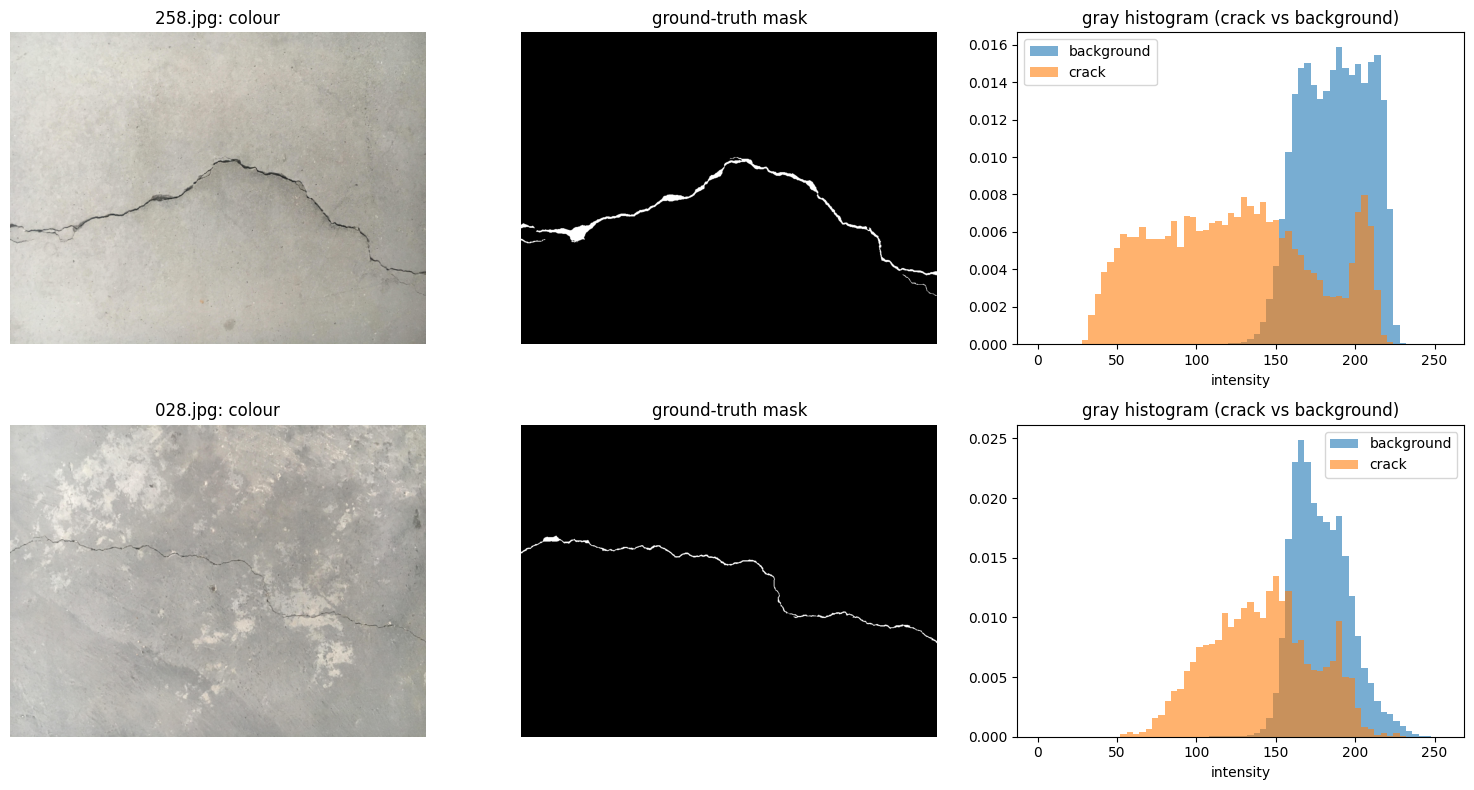

In [8]:
def mask_of(image_name):
    return dev_data.loc[dev_data.image == image_name, 'mask'].iloc[0]


fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for row, name in enumerate([typical, difficult]):
    rgb, gray, mask = load_pair(name, mask_of(name))
    axes[row, 0].imshow(rgb)
    axes[row, 0].set_title(f'{name}: colour')
    axes[row, 1].imshow(mask, cmap='gray')
    axes[row, 1].set_title('ground-truth mask')
    axes[row, 2].hist(gray[mask == 0].ravel(), bins=64, range=(0, 256),
                      alpha=0.6, density=True, label='background')
    if mask.sum():
        axes[row, 2].hist(gray[mask == 1].ravel(), bins=64, range=(0, 256),
                          alpha=0.6, density=True, label='crack')
    axes[row, 2].set_title('gray histogram (crack vs background)')
    axes[row, 2].set_xlabel('intensity')
    axes[row, 2].legend()
    axes[row, 0].axis('off')
    axes[row, 1].axis('off')
plt.tight_layout()
plt.show()

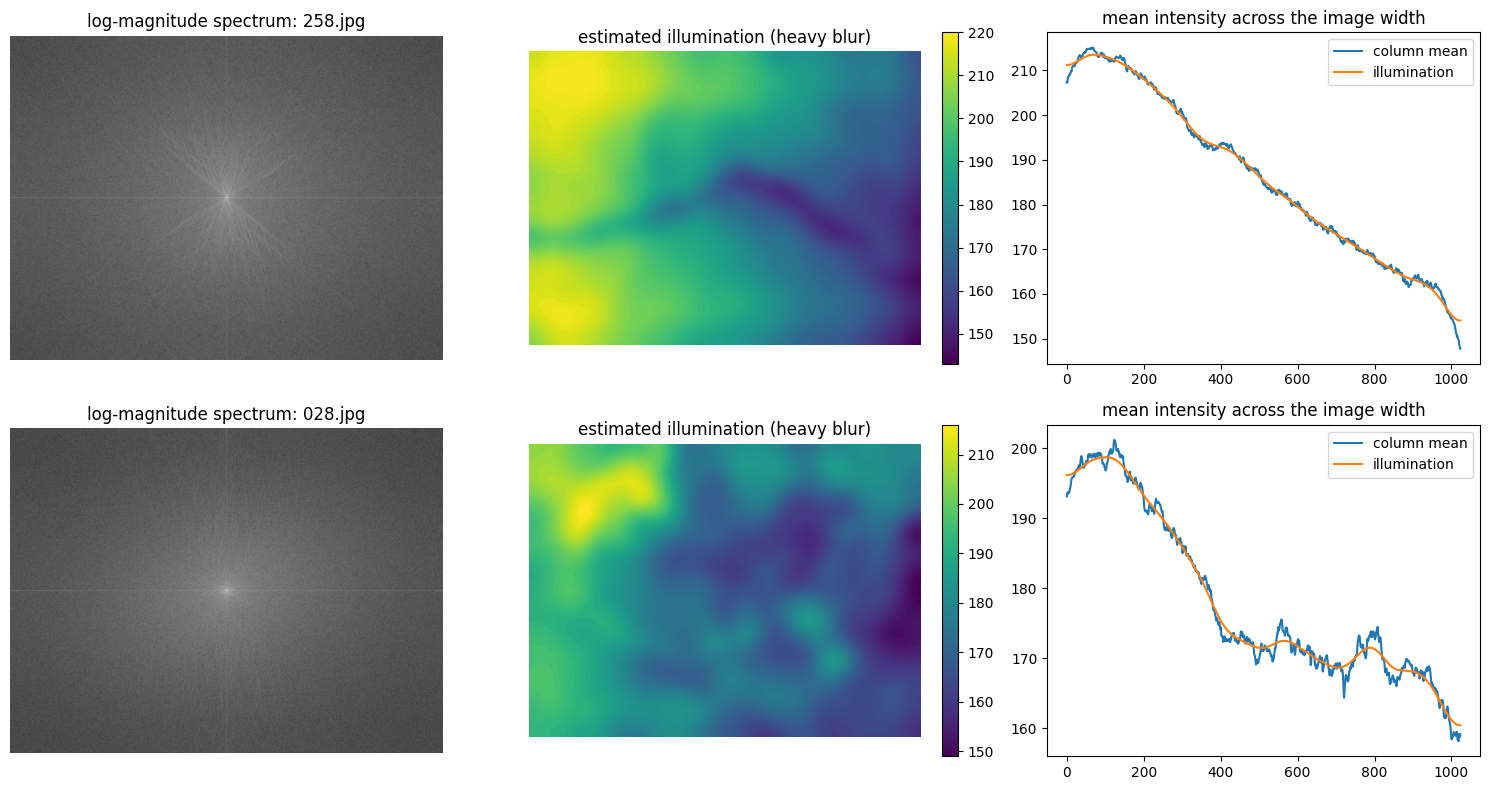

258.jpg: illumination range = 77 gray levels, noise sigma = 1.48
028.jpg: illumination range = 67 gray levels, noise sigma = 1.48


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
report = []
for row, name in enumerate([typical, difficult]):
    _, gray, mask = load_pair(name, mask_of(name))

    # centred log-magnitude Fourier spectrum
    spec = np.fft.fftshift(np.fft.fft2(gray.astype(np.float64)))
    axes[row, 0].imshow(np.log1p(np.abs(spec)), cmap='gray')
    axes[row, 0].set_title(f'log-magnitude spectrum: {name}')
    axes[row, 0].axis('off')

    # illumination: heavy blur approximates the slowly varying lighting
    k = int(min(gray.shape) // 4) | 1
    bg = cv2.GaussianBlur(gray, (k, k), 0)
    im = axes[row, 1].imshow(bg, cmap='viridis')
    axes[row, 1].set_title('estimated illumination (heavy blur)')
    axes[row, 1].axis('off')
    plt.colorbar(im, ax=axes[row, 1], fraction=0.046)

    # noise: robust sigma of the residual after a 3x3 median filter
    resid = gray.astype(np.float64) - cv2.medianBlur(gray, 3)
    sigma = 1.4826 * np.median(np.abs(resid - np.median(resid)))
    axes[row, 2].plot(gray.mean(axis=0), label='column mean')
    axes[row, 2].plot(bg.mean(axis=0), label='illumination')
    axes[row, 2].set_title('mean intensity across the image width')
    axes[row, 2].legend()
    report.append((name, int(bg.max()) - int(bg.min()), round(float(sigma), 2)))
plt.tight_layout()
plt.show()

for name, drift, sigma in report:
    print(f'{name}: illumination range = {drift} gray levels, noise sigma = {sigma}')

## 8. Spatial resolution and gray-level study (typical development image)

"Task still possible" is measured, not judged by eye. A setting is accepted when
(a) the ground-truth mask survives the reduction (IoU of the mask after shrinking and
re-expanding against the original mask is at least 0.7) and
(b) the simple baseline's IoU is at least 90 % of its value at full setting.

Settings are tested from the largest to the smallest and the search stops at the first
failure. If the baseline IoU at full setting is itself very low, criterion (b) is weak, so
rely mainly on (a) and say so in the report.

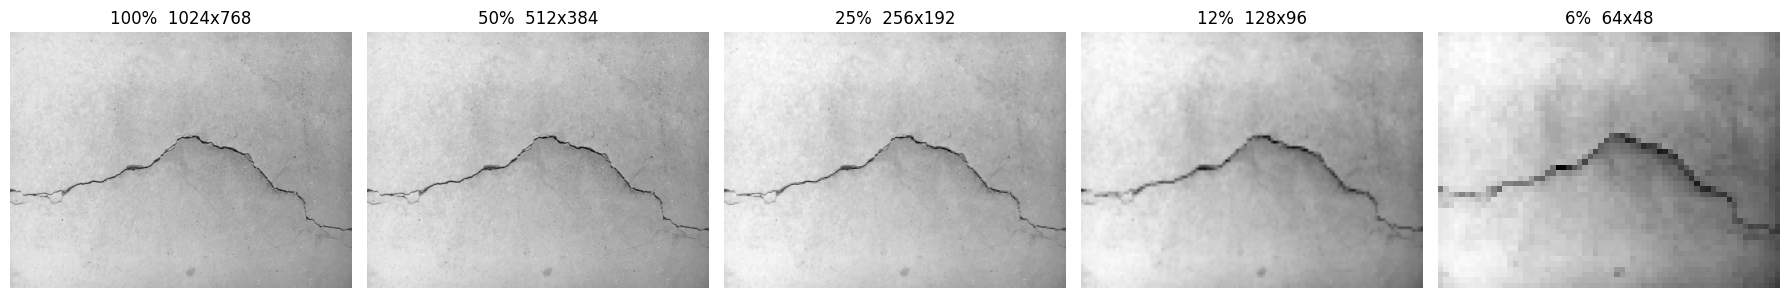

 scale     size  mask_survival_IoU  baseline_IoU  task_possible
1.0000 1024x768              1.000         0.023           True
0.5000  512x384              0.845         0.021           True
0.2500  256x192              0.626         0.018          False
0.1250   128x96              0.384         0.016          False
0.0625    64x48              0.195         0.016          False

Lowest acceptable resolution: 512x384


In [10]:
rgb, gray, mask = load_pair(typical, mask_of(typical))
h, w = gray.shape


def otsu_open_mask(g):
    """Otsu (dark objects = 1) followed by one 3x3 opening. Used by the study and baseline."""
    _, th = cv2.threshold(g, 0, 1, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
    return cv2.morphologyEx(th, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))


full_iou = iou_score(mask, otsu_open_mask(gray))
rows = []
fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, scale in zip(axes, [1.0, 0.5, 0.25, 0.125, 0.0625]):
    size = (max(1, int(w * scale)), max(1, int(h * scale)))
    g_small = cv2.resize(gray, size, interpolation=cv2.INTER_AREA)
    m_small = cv2.resize(mask, size, interpolation=cv2.INTER_NEAREST)
    m_back = cv2.resize(m_small, (w, h), interpolation=cv2.INTER_NEAREST)
    mask_keep = iou_score(mask, m_back)
    base_iou = iou_score(m_small, otsu_open_mask(g_small))
    ok = mask_keep >= 0.7 and base_iou >= 0.9 * full_iou
    rows.append({'scale': scale, 'size': f'{size[0]}x{size[1]}',
                 'mask_survival_IoU': round(mask_keep, 3),
                 'baseline_IoU': round(base_iou, 3), 'task_possible': ok})
    ax.imshow(g_small, cmap='gray')
    ax.set_title(f'{int(scale * 100)}%  {size[0]}x{size[1]}')
    ax.axis('off')
plt.tight_layout()
plt.show()

res_table = pd.DataFrame(rows)
print(res_table.to_string(index=False))
lowest = None
for _, r in res_table.iterrows():      # stop at the first setting that fails
    if not r['task_possible']:
        break
    lowest = r['size']
print('\nLowest acceptable resolution:', lowest or 'none of the tested settings')

In [11]:
def quantize(g, levels):
    """Reduce a uint8 image to `levels` gray levels, rescaled to 0..255."""
    step = 256.0 / levels
    q = np.floor(g / step)
    return np.round(q * 255.0 / (levels - 1)).astype(np.uint8)


def adaptive_open_mask(g):
    m = cv2.adaptiveThreshold(g, 1, cv2.ADAPTIVE_THRESH_MEAN_C,
                              cv2.THRESH_BINARY_INV, 51, 10)
    return cv2.morphologyEx(m, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))


study = dev_data.sample(min(20, len(dev_data)), random_state=SEED)
pairs = [load_pair(r['image'], r['mask'])[1:] for _, r in study.iterrows()]

rows = []
for lv in [256, 64, 16, 8, 4, 2]:
    scores = [iou_score(m, adaptive_open_mask(quantize(g, lv))) for g, m in pairs]
    rows.append({'gray_levels': lv, 'mean_IoU': round(float(np.mean(scores)), 3)})

gl_table = pd.DataFrame(rows)
full = gl_table.loc[gl_table.gray_levels == 256, 'mean_IoU'].iloc[0]
gl_table['task_possible'] = gl_table.mean_IoU >= 0.9 * full
print(f'Adaptive-threshold baseline, mean over {len(pairs)} dev images')
print(gl_table.to_string(index=False))

lowest = None
for _, r in gl_table.iterrows():
    if not r['task_possible']:
        break
    lowest = int(r['gray_levels'])
print('\nLowest acceptable number of gray levels:', lowest or 'none of the tested')


Adaptive-threshold baseline, mean over 20 dev images
 gray_levels  mean_IoU  task_possible
         256     0.312           True
          64     0.304           True
          16     0.177          False
           8     0.113          False
           4     0.103          False
           2     0.417           True

Lowest acceptable number of gray levels: 64


## 9. Findings and design decisions

| # | Finding (evidence from the cells above) | Design decision for the pipelines |
|---|---|---|
| 1 | Cracks cover only 0.51% to 2.79% of the pixels (mean 1.36%). | Use IoU, not accuracy. Report precision and recall too. |
| 2 | Crack and background histograms overlap strongly (crack mostly 50 to 150, background 150 to 220), mean contrast 69.8 gray levels, minimum 37.5. | Compare global, Otsu and adaptive thresholding. Add contrast enhancement. |
| 3 | The illumination drifts by 77 and 67 gray levels across the two analysed images. The Otsu baseline marked the dark part of the wall as crack (mean IoU 0.063 against 0.447 for the fixed threshold). | Correct the background (subtract a heavy blur) or use adaptive thresholding. |
| 4 | Noise is low (sigma 1.48), so the false detections come from surface texture and shadows, not noise. | Smooth lightly and remove small objects after thresholding. |
| 5 | Cracks are thin dark lines in the ground-truth masks. | Use closing to reconnect cracks and compare structuring-element shape and size. |
| 6 | The lowest acceptable resolution is 512x384 and the lowest acceptable number of gray levels is 64 (mean IoU 0.304 against 0.312 at 256 levels, adaptive threshold on 20 dev images; it drops to 0.177 at 16 levels). | Do not shrink below 512x384 and keep at least 64 gray levels. |


## 10. Baselines (development set only)

* **Trivial baseline:** fixed global threshold at 127 on the raw grayscale image. Cracks are
  darker than the surface, so pixels below 127 are marked as crack.
* **Simple baseline:** Otsu threshold followed by one 3x3 opening.

In [12]:
def trivial_baseline(gray_img):
    """Fixed global threshold 127 on raw grayscale. uint8 in, binary 0/1 out."""
    return (gray_img < 127).astype(np.uint8)


def simple_baseline(gray_img):
    """Otsu threshold followed by one 3x3 opening. uint8 in, binary 0/1 out."""
    return otsu_open_mask(gray_img)


# sanity check on a tiny synthetic image
_toy = np.full((8, 8), 200, np.uint8)
_toy[2:6, :] = 30          # 4 rows thick, so a 3x3 opening keeps it
assert trivial_baseline(_toy)[2:6].all() and trivial_baseline(_toy)[:2].sum() == 0
assert simple_baseline(_toy)[3:5].all()
print('baseline sanity tests passed')

baseline sanity tests passed


In [13]:
def evaluate(method, rows_df):
    """Run `method` on every row of `rows_df`; return a per-image results table."""
    out = []
    for _, r in rows_df.iterrows():
        _, g, m = load_pair(r['image'], r['mask'])
        t0 = time.perf_counter()
        pred = method(g)
        dt = time.perf_counter() - t0
        prec, rec = precision_recall(m, pred)
        out.append({'image': r['image'], 'iou': iou_score(m, pred),
                    'precision': prec, 'recall': rec, 'time_s': dt})
    return pd.DataFrame(out)


results = {}
for label, fn in [('trivial', trivial_baseline), ('simple', simple_baseline)]:
    results[label] = evaluate(fn, dev_data)
    results[label].to_csv(OUT_DIR / f'dev_per_image_{label}.csv', index=False)

summary = []
for label, df in results.items():
    best, worst = df.loc[df.iou.idxmax()], df.loc[df.iou.idxmin()]
    summary.append({
        'baseline': label, 'mean_IoU': df.iou.mean(), 'std_IoU': df.iou.std(),
        'best_IoU': best.iou, 'best_image': best.image,
        'worst_IoU': worst.iou, 'worst_image': worst.image,
        'mean_precision': df.precision.mean(), 'mean_recall': df.recall.mean(),
        'mean_time_s': df.time_s.mean()})
summary = pd.DataFrame(summary)
summary.to_csv(OUT_DIR / 'baseline_results_dev.csv', index=False)
print(summary.round(4).to_string(index=False))

baseline  mean_IoU  std_IoU  best_IoU best_image  worst_IoU worst_image  mean_precision  mean_recall  mean_time_s
 trivial    0.4472    0.182    0.8416    530.JPG     0.0149     357.JPG          0.7271       0.6021       0.0003
  simple    0.0628    0.135    0.8210    489.JPG     0.0068     030.jpg          0.0825       0.8728       0.0015


In [14]:
LOG_FILE = OUT_DIR / 'experiment_log.csv'
LOG_COLUMNS = ['run_id', 'date', 'author', 'pipeline', 'stage', 'method',
               'parameters', 'seed', 'time_s', 'metric', 'dev_value']


def log_run(pipeline, stage, method, parameters, time_s, metric, value):
    """Append one run to the experiment log CSV (created on first use)."""
    prev = pd.read_csv(LOG_FILE) if LOG_FILE.exists() else pd.DataFrame(
        columns=LOG_COLUMNS)
    row = {'run_id': len(prev) + 1, 'date': datetime.date.today().isoformat(),
           'author': AUTHOR, 'pipeline': pipeline, 'stage': stage, 'method': method,
           'parameters': parameters, 'seed': SEED, 'time_s': round(time_s, 4),
           'metric': metric, 'dev_value': round(float(value), 4)}
    rows_all = prev.to_dict('records') + [row]
    pd.DataFrame(rows_all, columns=LOG_COLUMNS).to_csv(LOG_FILE, index=False)


if LOG_FILE.exists():
    LOG_FILE.unlink()          # start a fresh log each time this notebook is re-run
log_run('baseline', 'segmentation', 'fixed threshold', 'T=127',
        results['trivial'].time_s.mean(), 'mean IoU', results['trivial'].iou.mean())
log_run('baseline', 'segmentation', 'Otsu + opening', 'kernel=3x3 rect',
        results['simple'].time_s.mean(), 'mean IoU', results['simple'].iou.mean())
print(pd.read_csv(LOG_FILE).to_string(index=False))

 run_id       date author pipeline        stage          method      parameters  seed  time_s   metric  dev_value
      1 2026-11-26   team baseline segmentation fixed threshold           T=127    42  0.0003 mean IoU     0.4472
      2 2026-11-26   team baseline segmentation  Otsu + opening kernel=3x3 rect    42  0.0015 mean IoU     0.0628


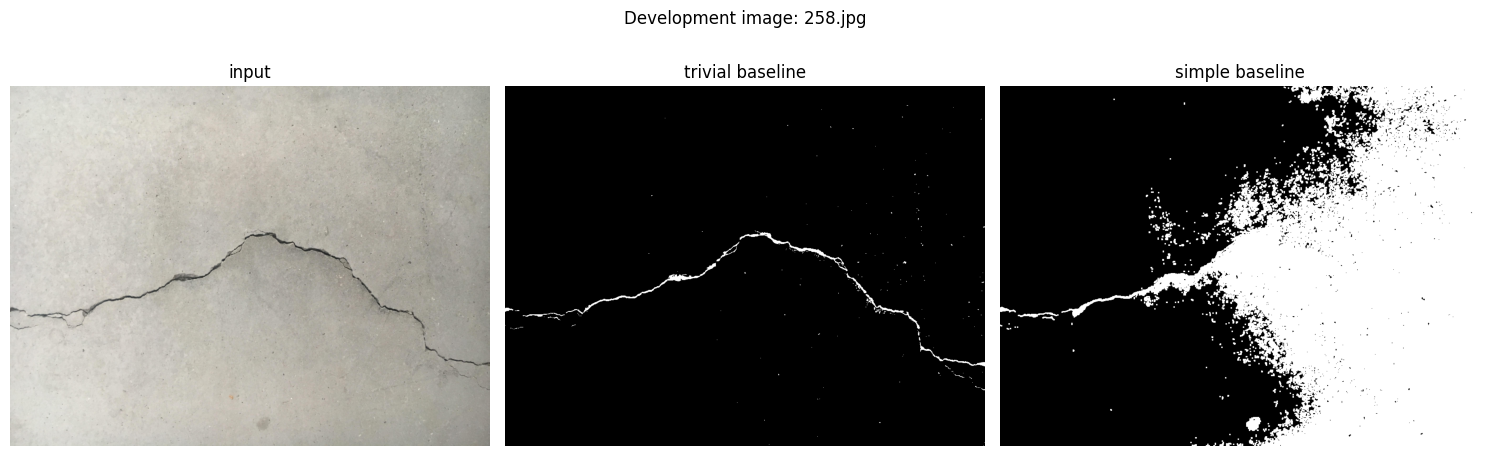

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('Development image: ' + typical)
rgb, gray, mask = load_pair(typical, mask_of(typical))
for ax, (title, img) in zip(axes, [
        ('input', rgb), ('trivial baseline', trivial_baseline(gray)),
        ('simple baseline', simple_baseline(gray))]):
    ax.imshow(img, cmap=None if img.ndim == 3 else 'gray')
    ax.set_title(title)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Notes

* Everything above uses the **development set only**. The test set (`outputs/test_set.csv`)
  stays untouched until the final evaluation.
* The two mean IoU values are measurements, not targets. If the simple baseline is worse
  than the trivial one, report it honestly and explain why.
* Outputs written to `outputs/`: `development_set.csv`, `test_set.csv`,
  `baseline_results_dev.csv`, per-image CSVs and `experiment_log.csv`.